# Pricing of options by Monte Carlo  


This notebook presents the basic functionalities of the MonteCarloPricing program, which uses Monte Carlo techniques to price options. 

We start by generating geometric Brownian motion (GBM) paths under the risk-neutral measure. 
Next, we use these paths to estimate European call and put prices and compare them against the analytical Black–Scholes formula. 

In [ ]:
# import necessary packages 

# for auto reloading  
%load_ext autoreload
%autoreload 2

import old_stuff.MonteCarloPricing as MonteCarloPricing
# import Plotting 

import numpy as np
import matplotlib.pyplot as plt 
# import scipy.stats as st

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Notation

| Notation | Explanation |
|----------|-------------|
| $S_0$ | Initial stock price |
| $K$ | Strike price |
| $T$ | Maturity |
| $r$ | Constant risk-free interest rate |
| $\sigma$ | Constant GBM volatility |
| $M$ | Number of time steps |
| $N$ | Number of paths |
| $S(t_i)$ | Exact stock price at time $t_i$ |
| $\widehat S_i^{(j)}$ | Numerical approximation for path $j$ at time $t_i$ |
| $W_t$ | Wiener process under the risk-neutral measure |
| $\Delta t$ | Time-step size $T/M$ |
| $\Delta W_i$ | Brownian increment $W(t_{i+1})-W(t_i)$ |
| $V(t_i,S)$ | Option value at time $t_i$ when the stock price is $S$ |
| $\Phi(T,S_T)$ | Payoff at maturity, with $\Phi(T,S_T)=V(T,S_T)$ |

## The Monte Carlo Pricing Algorithm

Let us recall the steps of Monte Carlo option pricing.

1. Partition $[0,T]$ using $t_i=iT/M$, with $i=0,\ldots,M$ and $\Delta t=T/M$.
2. Generate stock paths under the risk-neutral measure, with path index $j=1,\ldots,N$.
3. Compute the payoff $\Phi(T,S_T^{(j)})$ at maturity for every path.
4. Estimate the option value
   $$
   V(0,S_0)=e^{-rT}\mathbb E^{\mathbb Q}[\Phi(T,S_T)]
   $$
   using the discounted sample average
   $$
   \widehat V_N=e^{-rT}\frac1N\sum_{j=1}^N\Phi(T,S_T^{(j)}).
   $$
5. Estimate the standard error of the price estimator and construct an approximate 95% confidence interval.

<!-- For Euler and Milstein, the terminal values are numerical approximations, introducing discretization bias in addition to sampling error. For European options under GBM, we can also simulate terminal values directly without generating full paths. -->

## Generate GBM paths

Let us start by generating paths, which follow a geometric Brownian motion (GBM) dynamics 
$$
dS_t=rS_t\,dt+\sigma S_t\,dW_t.
$$
which has the exact solution
$$
S(t_{i+1})=S(t_i)\exp\left[
\left(r-\frac12\sigma^2\right)\Delta t+\sigma\Delta W_i
\right].
$$ 
<!-- In the stat_test_notebook.ipynb notebook we will use the exact solution to benchmark two different approxiamtion schemes, namely the euler and the milstein scheme. An into to this can be found in the  stat_test_notebook.ipynb notebook. -->

Price processes can be approximated by different kind of schemes, which use the Ito-Taylor expansion. We refere to the stat_test_notebook.ipynb notebook for an introduction to the Euler and Milstein scheme. There we will use the exact solution of the GBM process to benchmark the approximative schemes. Here we will consider only the GBM exact solution paths. 

In [ ]:
# Set parameters 
N = 2000    # number of paths
M = 1000    # number of time steps  
T = 1       # Maturity
r = 0.05    # interest_rate
sigma = 0.3 # volatility
S_0 = 50    # initial price

# we will consider the exact solution
scheme = "exact"

# get exact GBM paths 
paths = MonteCarloPricing.generate_GBM_paths(N, M, T, r, sigma, S_0, scheme)

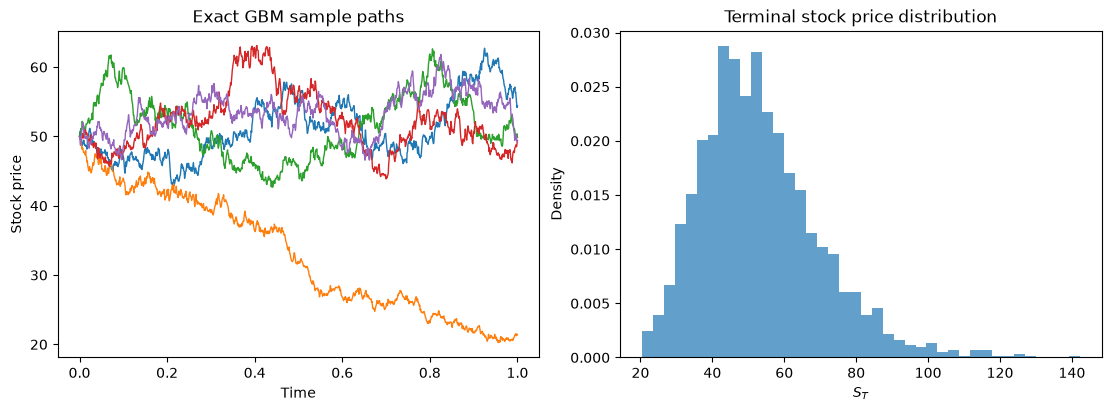

In [44]:
S = paths["S_exact"]
paths_to_show = 5

fig, (ax_paths, ax_hist) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)

# Show a few exact paths
ax_paths.plot(paths["time"], S[:paths_to_show].T, linewidth=1)
ax_paths.set(title="Exact GBM sample paths", xlabel="Time", ylabel="Stock price")

# Use all paths for the terminal distribution
ax_hist.hist(S[:, -1], bins=40, density=True, color="tab:blue", alpha=0.7)
ax_hist.set(title="Terminal stock price distribution", xlabel=r"$S_T$", ylabel="Density")

plt.show()

## Pricing of European call and put options 

Here we show how to estimate the price of a call option and then compare it to the analytical Black-Scholes formula

In [58]:
# Set parameters
N = 10000   # number of paths
# We set the number of time steps here to 1 since we only need the terminal exact value  
# For Euler or Milstein scheme we of course would need a finer discretization 
M = 1       # number of time steps 
T = 1       # Maturity
r = 0.06    # interest_rate
sigma = 0.3 # volatility
S_0 = 5     # initial price
K = 4.5     # strike 

# choose a seed for the rng
seed = 1000
np.random.seed(seed)

# choose "call" or "put" option
option_type = "call"

# we will consider the exact solution
scheme = "exact"

# generate exact GBM paths and select terminal values of all paths
S_T = (MonteCarloPricing.generate_GBM_paths(N, M, T, r, sigma, S_0, scheme))["S_exact"][:,-1]

# calculate price of a call option by MC
mc_call_price = MonteCarloPricing.mc_call_put_price(option_type,S_T,K,T,r)

# calculate price of a call option by black-scholes formula
analytical_call_price = (MonteCarloPricing.analytical_BS_call_put_price(option_type,S_0,K,T,r,sigma))

# compare the prices 
print(f"Monte Carlo price:\t{mc_call_price["price"]:.3f} +- {mc_call_price["standard_error"]:.3f}")
print(f"Black-Scholes price:\t{analytical_call_price:.3f}")
print(f"Error between the two:\t{mc_call_price["price"]-analytical_call_price:.3f}")

Monte Carlo price:	1.008 +- 0.013
Black-Scholes price:	1.013
Error between the two:	-0.005


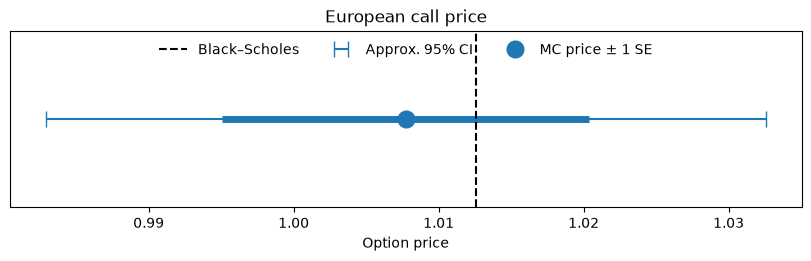

In [56]:
price = mc_call_price["price"]
se = mc_call_price["standard_error"]

fig, ax = plt.subplots(figsize=(8, 2.5), constrained_layout=True)

ax.errorbar(price, 0, xerr=1.96 * se, fmt="none", ecolor="tab:blue",
            capsize=6, label="Approx. 95% CI")
ax.errorbar(price, 0, xerr=se, fmt="o", markersize=12, color="tab:blue",
            elinewidth=5, label="MC price ± 1 SE")
ax.axvline(analytical_call_price, color="black", linestyle="--",
           label="Black–Scholes")

ax.set(title=f"European {option_type} price", xlabel="Option price", ylim=(-1, 1))
ax.set_yticks([])
ax.legend(loc="upper center", ncol=3, frameon=False)
plt.show()

The Monte Carlo estimate of 1.008 differs from the Black–Scholes price of 1.013 by -0.005, less than one estimated standard error of 0.013.